**PRÁCTICA 4 - Introducción a los biopotenciales y adquisición de señales ECG y EMG**

Integrantes: 

- Valentina Morales
- Paula García


---

**5.1 Esquema y registro de biopotenciales**

La señal bioeléctrica generada por el cuerpo se capta mediante electrodos desechables de Ag/AgCl, que actúan como transductores: convierten la corriente iónica del tejido en corriente eléctrica. Antes de colocarlos, la piel se limpió con alcohol y se dejó secar, para reducir la impedancia de contacto.

Las señales (del orden de milivoltios) entran al shield Olimex SHIELD-EKG-EMG, que realiza el acondicionamiento analógico. Según la hoja de datos del fabricante, consta de un amplificador de instrumentación diferencial (G1 = 10), una etapa de ganancia ajustable (G2 entre 6 y 101) y un filtro pasa-bajos de tercer orden con frecuencia de corte de 40 Hz (G3 = 3.56), con una ganancia total de aproximadamente 2848 por defecto [1]. Amplificar la señal permite aprovechar el rango de entrada del ADC (0–5 V), y el filtrado limita el ancho de banda y atenúa el ruido fuera de la banda de interés.

La salida analógica se conecta al pin A0 del Arduino UNO, cuyo conversor analógico-digital de 10 bits entrega valores entre 0 y 1023. Estos se envían por el puerto serial USB a 9600 baudios y se leen en Python con la librería PySerial, donde se almacenan en un archivo de texto y se grafican. El Arduino toma una muestra cada 10 ms aproximadamente (delay(10)), es decir, una frecuencia de muestreo nominal cercana a 100 Hz.

![Figura 1](esquema_5_1.png)

Figura 1. Etapas del sistema de adquisición utilizado: electrodos de Ag/AgCl, acondicionamiento analógico en el shield Olimex EKG/EMG (amplificador de instrumentación, ganancia ajustable y filtro pasa-bajos), digitalización con el ADC de 10 bits del Arduino UNO y transmisión serial al PC

---

**5.2 Fuentes de ruido en el registro de biopotenciales**

| Fuente de ruido | ¿Estática o variante? | Estrategias de control |
|---|---|---|
| Potencial de media celda (offset DC del electrodo) | Estática (casi constante si el contacto es estable) | Electrodos de Ag/AgCl, filtro pasa-altos, acople AC |
| Impedancia piel-electrodo | Variante (cambia con sudor, humedad y secado del gel) | Limpiar y abrasionar la piel, gel, amplificador con alta impedancia de entrada |
| Interferencia de red (60 Hz) | Frecuencia fija, amplitud variable | Amplificador de instrumentación (CMRR), cables cortos y blindados, balancear impedancias, pierna derecha activa (DRL), filtro notch |
| Artefactos de movimiento | Variante | Fijar bien electrodos y cables, paciente quieto, filtro pasa-altos, procesamiento digital |
| Otras bioseñales (p. ej. EMG sobre ECG) | Variante | Buena ubicación de electrodos, relajación del paciente, filtrado por banda |
| Deriva de línea base (respiración) | Variante (lenta) | Filtro pasa-altos de frecuencia de corte baja, paciente en reposo |
| Ruido electrónico (térmico, del amplificador) | Estática (estadísticamente constante) | Componentes de bajo ruido, ganancia adecuada, filtro pasa-bajos |
| Ruido de cuantización del ADC | Estática | Mayor resolución, ajustar la ganancia al rango del ADC |
| Aliasing | Depende de fs | Filtro antialiasing y fs adecuada |

Las fuentes de ruido se clasificaron según su comportamiento temporal: estáticas cuando su valor se mantiene aproximadamente constante durante el registro, y variantes cuando cambian con el tiempo o con las condiciones de adquisición. La mayoría de las fuentes asociadas al contacto y al paciente (impedancia piel-electrodo, movimiento, deriva de la línea base y otras bioseñales) son variantes, por lo que su control depende de la técnica de adquisición (preparación de la piel, fijación de electrodos, paciente en reposo). Las fuentes asociadas a la instrumentación (ruido electrónico, cuantización) son estáticas y se controlan con el diseño del sistema [2]. En el registro de ECG obtenido se observan pequeñas fluctuaciones sobre la línea base, cuyo origen no puede determinarse únicamente a partir de la gráfica.


---

**5.3 Acoplamiento piel-electrodo**

**Problemática.** La interfaz entre la piel y el electrodo no es un contacto eléctrico ideal: se comporta como una impedancia (resistencia en paralelo con capacitancia) más un potencial de media celda. Esa impedancia es alta, variable y diferente en cada electrodo, porque depende de la capa externa de la piel (células muertas, grasa, sudor), del vello, de la humedad y del estado del gel.
 Esto produce varios problemas: 
(i) pérdida de amplitud, porque la impedancia de la piel y la impedancia de entrada del amplificador forman un divisor de voltaje.
(ii) mayor interferencia de red, porque si las impedancias de los dos electrodos son distintas, la interferencia de modo común se convierte en una componente diferencial que el amplificador de instrumentación ya no puede rechazar.
(iii) artefactos de movimiento, porque cualquier desplazamiento del electrodo cambia la impedancia y el potencial de media celda, y genera variaciones en la línea base [2].

**Estrategias para mejorarlo.** Entre las más usadas están: preparar la piel (limpiar, retirar vello y, cuando se requiere, abrasionar suavemente), usar electrodos de Ag/AgCl con gel electrolítico, fijar bien electrodos y cables para evitar el movimiento, usar amplificadores con alta impedancia de entrada, y colocar el electrodo de referencia sobre una zona ósea con poca actividad muscular [2]. En este registro, la piel se limpió con alcohol y se dejó secar antes de colocar electrodos desechables de Ag/AgCl; los de referencia se ubicaron sobre la cresta ilíaca derecha (ECG) y sobre una prominencia ósea del codo (EMG).

**¿Por qué es la etapa más crítica?** Porque es la primera de la cadena de adquisición: lo que se pierda o se contamine aquí no se puede recuperar después. Las señales de superficie son de muy baja amplitud (del orden de milivoltios en ECG y EMG, y de microvoltios en EEG), de modo que el ruido y la pérdida de señal introducidos en el contacto pesan mucho en comparación con la señal. Además, todas las etapas posteriores (amplificación, filtrado, conversión A/D) amplifican por igual señal y ruido, y los filtros no pueden separar un artefacto cuyo contenido en frecuencia coincide con el de la señal de interés, como ocurre con los artefactos de movimiento en la banda del ECG [2].


---

**5.4 Análisis de la Variabilidad de la frecuencia cardíaca (HRV)**

1. Detección de picos R

NK-neurokit          TP/FP/FN = (np.int64(14), np.int64(0), np.int64(1))
NK-pantompkins1985   TP/FP/FN = (np.int64(10), np.int64(4), np.int64(5))
NK-hamilton2002      TP/FP/FN = (np.int64(6), np.int64(10), np.int64(9))
NK-elgendi2010       TP/FP/FN = (np.int64(13), np.int64(1), np.int64(2))
DET-pan_tompkins     TP/FP/FN = (np.int64(1), np.int64(13), np.int64(14))
DET-hamilton         TP/FP/FN = (np.int64(2), np.int64(12), np.int64(13))
DET-christov         TP/FP/FN = (np.int64(14), np.int64(0), np.int64(1))
DET-two_average      TP/FP/FN = (np.int64(0), np.int64(13), np.int64(15))


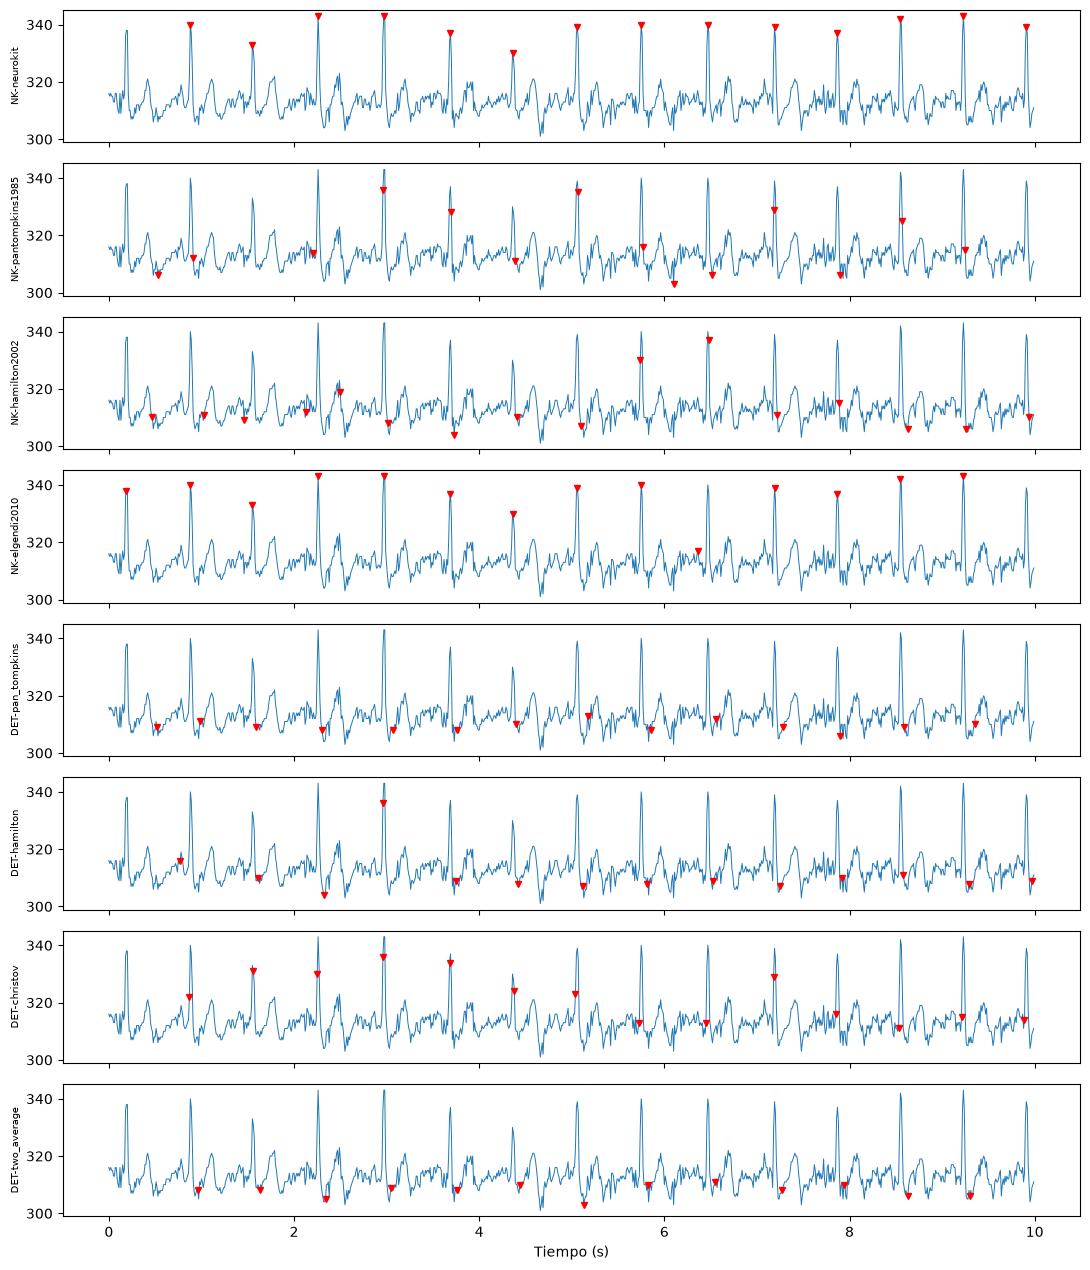

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk
from ecgdetectors import Detectors
from scipy.signal import find_peaks

import astropy.stats, astropy.timeseries
astropy.stats.LombScargle = astropy.timeseries.LombScargle   # compatibilidad: hrv-analysis usa la ruta vieja

from hrvanalysis import get_time_domain_features
from hrvanalysis import get_time_domain_features

fs = 100                      # Hz, frecuencia de muestreo nominal (delay(10) = 10 ms)
ecg = np.loadtxt("ecg.txt")   # 1000 muestras en cuentas del ADC
t = np.arange(len(ecg)) / fs  # eje de tiempo en segundos

picos = {}

# NeuroKit: ecg_peaks devuelve (señales, info); los picos están en info["ECG_R_Peaks"]
for m in ["neurokit", "pantompkins1985", "hamilton2002", "elgendi2010"]:
    _, info = nk.ecg_peaks(ecg, sampling_rate=fs, method=m)
    picos["NK-" + m] = np.asarray(info["ECG_R_Peaks"])

# Detectors: se crea el objeto con fs y cada detector recibe la señal
det = Detectors(fs)
picos["DET-pan_tompkins"] = np.asarray(det.pan_tompkins_detector(ecg))
picos["DET-hamilton"]     = np.asarray(det.hamilton_detector(ecg))
picos["DET-christov"]     = np.asarray(det.christov_detector(ecg))
picos["DET-two_average"]  = np.asarray(det.two_average_detector(ecg))

# Referencia: 15 picos verificados visualmente (umbral = mediana + 15 cuentas, válido para ESTA señal)
ref, _ = find_peaks(ecg, height=np.median(ecg) + 15, distance=40)

def evaluar(p, ref, tol=3):
    tp = sum(np.any(np.abs(ref - q) <= tol) for q in p)
    fp = len(p) - tp
    fn = len(ref) - sum(np.any(np.abs(p - r) <= tol) for r in ref)
    return tp, fp, fn

for nombre, p in picos.items():
    print(f"{nombre:20s} TP/FP/FN = {evaluar(p, ref)}")

# Figura: señal con picos marcados
fig, ax = plt.subplots(len(picos), 1, figsize=(11, 1.6*len(picos)), sharex=True)
for a, (n, p) in zip(ax, picos.items()):
    a.plot(t, ecg, lw=0.7); a.plot(p/fs, ecg[p], "rv", ms=4); a.set_ylabel(n, fontsize=7)
ax[-1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

Se detectaron los picos R del registro de ECG (1000 muestras, fs nominal = 100 Hz) con dos librerías: cuatro métodos de NeuroKit2 (`neurokit`, `pantompkins1985`, `hamilton2002`, `elgendi2010`) y cuatro detectores de la librería Detectors (`pan_tompkins`, `hamilton`, `christov`, `two_average`).

**Criterio de comparación.** No se dispone de anotaciones de referencia de un especialista, por lo que se tomó como referencia los 15 picos R identificados visualmente en la señal (obtenidos con `find_peaks` y verificados sobre la gráfica). Un pico detectado se consideró acierto (TP) si estaba a ±3 muestras (30 ms) de un pico de referencia; falso positivo (FP) si no correspondía a ninguno; y falso negativo (FN) si un pico de referencia no fue detectado.

| Algoritmo | TP | FP | FN |
|---|---|---|---|
| NeuroKit `neurokit` | 14 | 0 | 1 |
| Detectors `christov` | 14 | 0 | 1 |
| NeuroKit `elgendi2010` | 13 | 1 | 2 |
| NeuroKit `pantompkins1985` | 10 | 4 | 5 |
| NeuroKit `hamilton2002` | 6 | 10 | 9 |
| Detectors `pan_tompkins` | 1 | 13 | 14 |
| Detectors `hamilton` | 2 | 12 | 13 |
| Detectors `two_average` | 0 | 13 | 15 |

**Resultado.** El método `neurokit` detectó 14 de los 15 picos sin falsos positivos (se omitió el primero, ubicado en el borde del registro), y fue el que ubicó los marcadores directamente sobre la cima del complejo QRS (Figura X). `christov` obtuvo el mismo conteo, pero sus marcas quedan desplazadas respecto a la cima. Varios detectores clásicos (Pan-Tompkins, Hamilton, Two-average) fallaron casi por completo, marcando ondas T y valles de la línea base; una posible causa es que fueron diseñados para frecuencias de muestreo mayores que los 100 Hz de este registro (hipótesis por verificar en los artículos originales).

**Conclusión.** En este registro el algoritmo que mejor detecta los picos R es el de **NeuroKit (`neurokit`)**. Esta conclusión se limita a una señal de unos 10 s con una referencia verificada visualmente, por lo que no puede generalizarse.

---

2. Variabilidad de la frecuencia cardíaca (HRV) a partir de los picos R detectados.

R-R (ms): [670, 710, 710, 720, 670, 700, 690, 720, 720, 680, 680, 680, 680]
mean_nni       694.62
sdnn            19.41
sdsd            25.32
nni_50           0.00
pnni_50          0.00
nni_20           5.00
pnni_20         41.67
rmssd           25.33
median_nni     690.00
range_nni       50.00
cvsd             0.04
cvnni            0.03
mean_hr         86.44
max_hr          89.55
min_hr          83.33
std_hr           2.31


<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

...

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

<Figure size 800x300 with 0 Axes>

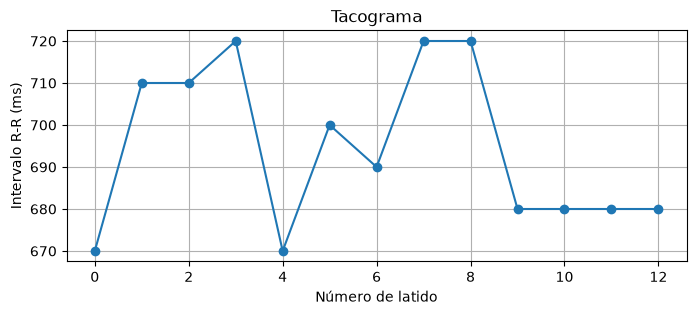

In [4]:
p = picos["NK-neurokit"]               # mejor algoritmo según la celda anterior
rr_ms = list(np.diff(p) / fs * 1000)   # intervalos R-R en milisegundos
print("R-R (ms):", [round(x) for x in rr_ms])

rasgos = get_time_domain_features(rr_ms)   # espera intervalos en ms
for k, v in rasgos.items():
    print(f"{k:12s} {v:8.2f}")

    plt.figure(figsize=(8, 3))
plt.plot(rr_ms, "o-")
plt.xlabel("Número de latido")
plt.ylabel("Intervalo R-R (ms)")
plt.title("Tacograma")
plt.grid(True)
plt.show()

La HRV describe la variación del intervalo de tiempo entre latidos consecutivos. Para calcularla se tomaron los picos R detectados con `neurokit` y se obtuvo la serie de intervalos R-R restando las posiciones de picos consecutivos y convirtiendo de muestras a milisegundos (R-R = Δmuestras / fs × 1000). Se obtuvieron 13 intervalos: 670, 710, 710, 720, 670, 700, 690, 720, 720, 680, 680, 680 y 680 ms, con una media de 694.6 ms (≈ 86.4 lpm). La Figura 3 muestra el tacograma de la serie.

No se aplicó ningún preprocesamiento (eliminación de latidos ectópicos ni interpolación), pues en la inspección visual de la señal no se observaron latidos anómalos.

La función `get_time_domain_features(nn_intervals)` de la librería `hrvanalysis` recibe la serie de intervalos entre latidos normales (NN) **en milisegundos** y devuelve un diccionario con las medidas estadísticas clásicas de HRV en el dominio del tiempo. Se implementó en la celda anterior sobre los 13 intervalos R-R obtenidos con `neurokit` (`rasgos = get_time_domain_features(rr_ms)`). Las medidas se agrupan en dos tipos [3], [4]:

- **Medidas sobre los intervalos** (variabilidad global): media, mediana, rango, SDNN y CVNN.
- **Medidas sobre las diferencias entre intervalos sucesivos** (variabilidad latido a latido, asociada principalmente a la actividad vagal): RMSSD, SDSD, NN50, pNN50, NN20, pNN20 y CVSD.

| Característica | Definición | Valor obtenido |
|---|---|---|
| `mean_nni` | Media de los intervalos NN | 694.62 ms |
| `median_nni` | Mediana de los intervalos NN | 690.00 ms |
| `range_nni` | Diferencia entre el intervalo máximo y el mínimo | 50.00 ms |
| `sdnn` | Desviación estándar de los intervalos NN; refleja la variabilidad total | 19.41 ms |
| `cvnni` | Coeficiente de variación: SDNN / media NN | 0.03 |
| `rmssd` | Raíz cuadrática media de las diferencias entre intervalos sucesivos; refleja la variabilidad de corto plazo (vagal) | 25.33 ms |
| `sdsd` | Desviación estándar de las diferencias entre intervalos sucesivos | 25.32 ms |
| `cvsd` | RMSSD / media NN | 0.04 |
| `nni_50` / `pnni_50` | Número / porcentaje de diferencias sucesivas mayores a 50 ms | 0 / 0 % |
| `nni_20` / `pnni_20` | Número / porcentaje de diferencias sucesivas mayores a 20 ms | 5 / 41.67 % |
| `mean_hr` | Frecuencia cardíaca media | 86.44 lpm |
| `max_hr` / `min_hr` | Frecuencia cardíaca máxima / mínima (a partir del intervalo NN más corto / más largo) | 89.55 / 83.33 lpm |
| `std_hr` | Desviación estándar de la frecuencia cardíaca | 2.31 lpm |

Los valores se verificaron recalculando a mano SDNN (desviación estándar muestral) y RMSSD a partir de la serie R-R, con los mismos resultados. Los porcentajes pNN50 y pNN20 se calculan sobre las 12 diferencias sucesivas (5/12 = 41.67 %).

**Interpretación.** La frecuencia cardíaca media (86.4 lpm) está dentro del rango normal en reposo. SDNN (19.4 ms) y RMSSD (25.3 ms) son menores que los valores de referencia de corto plazo reportados para adultos sanos (SDNN ≈ 50 ± 16 ms y RMSSD ≈ 42 ± 15 ms en registros de 5 min [5]), y pNN50 fue 0 %. Sin embargo, estos valores **no son comparables directamente** con las referencias por dos limitaciones del registro:

1. **Duración.** Se analizaron unos 10 s (13 intervalos), mientras que el estándar para HRV de corto plazo es de 5 min [3], y la guía de la práctica pedía al menos 1 min. SDNN depende de la duración del registro: en ventanas cortas no alcanza a capturar las oscilaciones lentas (por ejemplo, las asociadas a la respiración, de unos 4 a 5 s por ciclo, apenas aparecen 2 o 3 veces), por lo que tiende a subestimarse. RMSSD es la medida más robusta en registros ultracortos [6], pero aun así 10 s es un tiempo muy limitado.
2. **Resolución temporal.** Con fs = 100 Hz cada intervalo R-R solo puede medirse en múltiplos de 10 ms (todos los valores obtenidos terminan en 0). Esto introduce un error de cuantización de hasta ±10 ms en cada diferencia sucesiva, del mismo orden que las diferencias que se quieren medir, y afecta especialmente a NN20, NN50 y RMSSD. La guía de la Task Force recomienda frecuencias de muestreo de 250 a 500 Hz para análisis de HRV [3].


5.5 Consulte tres aplicaciones clínicas del uso de ECG y EMG (seis aplicaciones en total, tres por cada tipo de señal), el tipo de registro y procesamiento que se utiliza en cada una de el

**Electrocardiografía (ECG)**

| Aplicación | Tipo de registro | Procesamiento |
|---|---|---|
| **Detección de arritmias (p. ej. fibrilación auricular, pausas, taquicardias)** | ECG ambulatorio tipo Holter: 2 o 3 canales durante 24 a 48 h (o monitores de eventos por varias semanas) mientras el paciente hace su vida normal [9] | Filtrado de ruido y deriva de línea base, detección de complejos QRS (p. ej. Pan-Tompkins [7]), clasificación de latidos (normales, ectópicos), análisis de la regularidad de los intervalos R-R para detectar fibrilación auricular, y reporte de eventos para revisión del cardiólogo |
| **Diagnóstico de isquemia e infarto agudo de miocardio** | ECG de reposo de 12 derivaciones (10 electrodos), unos 10 s, con ancho de banda diagnóstico de 0.05 a 150 Hz [11]; también prueba de esfuerzo con registro continuo durante el ejercicio | Eliminación de la deriva de línea base sin distorsionar el segmento ST (por eso el pasa-altos debe ser de muy baja frecuencia), promediado de latidos, medición automática del desnivel del segmento ST en el punto J y de las ondas Q y T, comparado con los criterios de la definición universal de infarto [10] |
| **Evaluación del sistema nervioso autónomo mediante HRV** (estratificación de riesgo después de un infarto, neuropatía autonómica diabética) | Registros de corto plazo (5 min en reposo controlado) o de largo plazo (Holter de 24 h), con fs de 250 a 500 Hz [3] | Detección de picos R, corrección o eliminación de latidos ectópicos, construcción de la serie R-R y cálculo de índices en el dominio del tiempo (SDNN, RMSSD, pNN50) y de la frecuencia (potencias LF y HF) [3], [4] |

**Electromiografía (EMG)**

| Aplicación | Tipo de registro | Procesamiento |
|---|---|---|
| **Diagnóstico de enfermedades neuromusculares** (diferenciar neuropatías, como la esclerosis lateral amiotrófica o la radiculopatía, de miopatías) | EMG invasivo con electrodo de aguja concéntrico insertado en el músculo, en reposo y durante contracción voluntaria progresiva; suele acompañarse de estudios de conducción nerviosa [12] | Análisis de la actividad espontánea en reposo (fibrilaciones, ondas positivas, fasciculaciones) y de los potenciales de acción de unidad motora: amplitud, duración, número de fases y patrón de reclutamiento. Por ejemplo, potenciales grandes y prolongados sugieren neuropatía, y pequeños y polifásicos sugieren miopatía [12] |
| **Control de prótesis mioeléctricas** de miembro superior | EMG de superficie con varios canales sobre los músculos del muñón (p. ej. flexores y extensores del antebrazo), registro continuo durante el uso | Filtrado pasa-banda (aprox. 20 a 450 Hz), segmentación en ventanas cortas (≈ 100 a 250 ms), extracción de características (valor absoluto medio, cruces por cero, longitud de onda, RMS) y clasificación de patrones (p. ej. análisis discriminante lineal) para decidir el movimiento de la prótesis en tiempo real [13], [14] |
| **Evaluación de fatiga muscular y rehabilitación** (biomecánica, medicina deportiva, biorretroalimentación) | EMG de superficie con electrodos bipolares ubicados según las recomendaciones SENIAM [16], durante contracciones sostenidas o tareas dinámicas como la marcha | Rectificación y suavizado para obtener la envolvente (nivel y tiempos de activación del músculo); análisis espectral (FFT) para seguir la frecuencia media o mediana, cuyo descenso progresivo durante una contracción sostenida es un indicador de fatiga [15], [17] |


5.6 Adjunte al menos tres conclusiones, y referencias bibliográficas apropiadas y suficientes (evitar el uso de páginas web y preferir el uso de artículos académicos)

1. **La calidad del registro depende principalmente de las primeras etapas de la cadena de adquisición.** El acoplamiento piel-electrodo y el acondicionamiento analógico determinan la relación señal-ruido de la señal que llega al ADC. Con una preparación sencilla de la piel (alcohol) y el shield Olimex se obtuvo un ECG en el que los complejos QRS se distinguen con claridad, pero con pequeñas fluctuaciones en la línea base que el procesamiento digital posterior no puede separar por completo de la señal.

2. **El desempeño de los detectores de picos R depende de las condiciones de adquisición para las que fueron diseñados.** Sobre el mismo registro, el método `neurokit` detectó 14 de 15 picos sin falsos positivos, mientras que las implementaciones de Pan-Tompkins, Hamilton y Two-average de la librería Detectors fallaron casi por completo. Esto es coherente con la hipótesis planteada en 5.4.1: el algoritmo de Pan-Tompkins se diseñó con filtros calculados para una frecuencia de muestreo de 200 Hz [7], el doble de la usada en esta práctica (100 Hz). Por eso, antes de usar un detector se debe validar sobre la propia señal y no asumir que funciona solo porque es un algoritmo clásico.

3. **Las características de HRV obtenidas deben interpretarse con precaución por la duración y la frecuencia de muestreo del registro.** Con unos 10 s de señal y fs = 100 Hz se obtuvieron SDNN = 19.4 ms y RMSSD = 25.3 ms, con intervalos R-R cuantizados en pasos de 10 ms. Un análisis de HRV con valor fisiológico requiere al menos 5 min de registro en reposo y frecuencias de muestreo de 250 a 500 Hz [3]. En el sistema utilizado, la fs podría aumentarse reduciendo el `delay(10)` del Arduino y la velocidad del puerto serial, y el registro debería prolongarse como mínimo al minuto indicado en la guía.

4. **El ECG y el EMG comparten los mismos principios de adquisición, pero sus aplicaciones clínicas exigen registros y procesamientos distintos.** En el ECG el interés está en la morfología y la temporización de cada latido (arritmias, segmento ST, HRV), mientras que en el EMG está en la amplitud y el contenido en frecuencia de una señal de tipo estocástico (envolvente, características para clasificación, frecuencia mediana para fatiga). Esto se refleja también en el ancho de banda: el filtro pasa-bajos de 40 Hz del shield es adecuado para monitorear el ECG, pero recorta buena parte del contenido del EMG de superficie, que se extiende hasta unos 400 a 500 Hz [16].

**REFERENCIAS**

[1] Olimex Ltd., “SHIELD-EKG-EMG.” [En línea]. Disponible: https://www.olimex.com/Products/Duino/Shields/SHIELD-EKG-EMG/

[2] J. G. Webster, Ed., Medical Instrumentation: Application and Design, 4.ª ed. John Wiley & Sons, 2009

[3] Task Force of the European Society of Cardiology and the North American Society of Pacing and Electrophysiology, "Heart rate variability: Standards of measurement, physiological interpretation, and clinical use," *Circulation*, vol. 93, no. 5, pp. 1043–1065, 1996.

[4] F. Shaffer y J. P. Ginsberg, "An overview of heart rate variability metrics and norms," *Frontiers in Public Health*, vol. 5, art. 258, 2017.

[5] D. Nunan, G. R. H. Sandercock y D. A. Brodie, "A quantitative systematic review of normal values for short-term heart rate variability in healthy adults," *Pacing and Clinical Electrophysiology*, vol. 33, no. 11, pp. 1407–1417, 2010.

[6] M. L. Munoz *et al.*, "Validity of (ultra-)short recordings for heart rate variability measurements," *PLoS ONE*, vol. 10, no. 9, e0138921, 2015.

[7] J. Pan y W. J. Tompkins, "A real-time QRS detection algorithm," *IEEE Transactions on Biomedical Engineering*, vol. BME-32, no. 3, pp. 230–236, 1985.

[8] D. Makowski *et al.*, "NeuroKit2: A Python toolbox for neurophysiological signal processing," *Behavior Research Methods*, vol. 53, no. 4, pp. 1689–1696, 2021.

[9] J. S. Steinberg *et al.*, "2017 ISHNE-HRS expert consensus statement on ambulatory ECG and external cardiac monitoring/telemetry," *Heart Rhythm*, vol. 14, no. 7, pp. e55–e96, 2017.

[10] K. Thygesen *et al.*, "Fourth universal definition of myocardial infarction (2018)," *Circulation*, vol. 138, no. 20, pp. e618–e651, 2018.

[11] P. Kligfield *et al.*, "Recommendations for the standardization and interpretation of the electrocardiogram: Part I," *Circulation*, vol. 115, no. 10, pp. 1306–1324, 2007.

[12] J. Kimura, *Electrodiagnosis in Diseases of Nerve and Muscle: Principles and Practice*, 4.ª ed. Oxford University Press, 2013.

[13] B. Hudgins, P. Parker y R. N. Scott, "A new strategy for multifunction myoelectric control," *IEEE Transactions on Biomedical Engineering*, vol. 40, no. 1, pp. 82–94, 1993.

[14] A. Phinyomark, P. Phukpattaranont y C. Limsakul, "Feature reduction and selection for EMG signal classification," *Expert Systems with Applications*, vol. 39, no. 8, pp. 7420–7431, 2012.

[15] M. Cifrek, V. Medved, S. Tonković y S. Ostojić, "Surface EMG based muscle fatigue evaluation in biomechanics," *Clinical Biomechanics*, vol. 24, no. 4, pp. 327–340, 2009.

[16] H. J. Hermens, B. Freriks, C. Disselhorst-Klug y G. Rau, "Development of recommendations for SEMG sensors and sensor placement procedures," *Journal of Electromyography and Kinesiology*, vol. 10, no. 5, pp. 361–374, 2000.

[17] C. J. De Luca, "The use of surface electromyography in biomechanics," *Journal of Applied Biomechanics*, vol. 13, no. 2, pp. 135–163, 1997.
